In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import leaves_list
from scipy.optimize import minimize

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

In [2]:
end_date = "2026-10-01"
start_date = "2016-10-01"
TICKERS = ["ABEV3.SA", "AXIA3.SA", "B3SA3.SA", "BBSE3.SA", "BBDC3.SA",
"BBDC4.SA", "SAUD3.SA", "BBAS3.SA","CMIG4.SA","CPLE3.SA", "CPFE3.SA",
"EMBJ3.SA", "ENGI11.SA", "ENEV3.SA", "EGIE3.SA", "EQTL3.SA", "GGBR4.SA",
"ISAE4.SA", "ITSA4.SA", "ITUB3.SA", "ITUB4.SA", "KLBN11.SA", "RENT3.SA",
"MBRF3.SA", "MOTV3.SA", "PETR3.SA", "PETR4.SA", "PSSA3.SA", "PRIO3.SA",
"RADL3.SA", "RAIL3.SA", "SBSP3.SA", "SANB11.SA", "SUZB3.SA", "VIVT3.SA",
"TIMS3.SA", "UGPA3.SA", "VALE3.SA", "WEGE3.SA"]

# Lista para armazenar as cotações das ações
stock_data = []

# Percorre cada ticker e coleta sua cotação
for ticker in tqdm(TICKERS):
    data = yf.Ticker(ticker).history(start= start_date , end= end_date)
    data['ticker'] = ticker

    # Checa se o ativo é válido e possui cotações no período
    if data.shape[0] > 0:
        stock_data.append(data)
    else:
        TICKERS.remove(ticker)

# Transforma stock_data em um dataframe, concatenando as cotações
stock_data = pd.concat(stock_data, axis=0)
stock_data

100%|██████████| 39/39 [00:06<00:00,  5.91it/s]


,Open,High,Low,Close,Volume,Dividends,Stock Splits,ticker
Date,,,,,,,,
2016-10-03 00:00:00-03:00,13.046289,13.125719,13.013194,13.072766,14082500,0.0,0.0,ABEV3.SA
2016-10-04 00:00:00-03:00,13.092624,13.092624,12.900669,12.933765,15795000,0.0,0.0,ABEV3.SA
2016-10-05 00:00:00-03:00,12.986719,13.066147,12.940384,12.966861,8711300,0.0,0.0,ABEV3.SA
2016-10-06 00:00:00-03:00,12.966861,13.052909,12.894050,13.006576,13265700,0.0,0.0,ABEV3.SA
2016-10-07 00:00:00-03:00,13.052909,13.066148,12.913908,13.006576,10876200,0.0,0.0,ABEV3.SA
...,...,...,...,...,...,...,...,...
2026-09-24 00:00:00-03:00,51.000000,51.320000,50.080002,50.740002,6455000,0.0,0.0,WEGE3.SA
2026-09-25 00:00:00-03:00,50.639999,51.259998,50.250000,51.070000,6029900,0.0,0.0,WEGE3.SA
2026-09-28 00:00:00-03:00,50.669998,51.360001,50.049999,50.119999,8194700,0.0,0.0,WEGE3.SA


In [3]:
# Número de observações por ticker
n_obs = stock_data.groupby('ticker').size()

print(n_obs.sort_values(ascending=False))

ticker
ABEV3.SA     2490
AXIA3.SA     2490
B3SA3.SA     2490
BBAS3.SA     2490
BBDC3.SA     2490
BBDC4.SA     2490
BBSE3.SA     2490
CMIG4.SA     2490
CPFE3.SA     2490
CPLE3.SA     2490
EGIE3.SA     2490
EMBJ3.SA     2490
ENEV3.SA     2490
ENGI11.SA    2490
EQTL3.SA     2490
GGBR4.SA     2490
ISAE4.SA     2490
ITSA4.SA     2490
ITUB3.SA     2490
ITUB4.SA     2490
KLBN11.SA    2490
MBRF3.SA     2490
MOTV3.SA     2490
PETR3.SA     2490
PETR4.SA     2490
PRIO3.SA     2490
PSSA3.SA     2490
RADL3.SA     2490
RAIL3.SA     2490
RENT3.SA     2490
SANB11.SA    2490
SAUD3.SA     2490
SBSP3.SA     2490
SUZB3.SA     2490
TIMS3.SA     2490
UGPA3.SA     2490
VALE3.SA     2490
VIVT3.SA     2490
WEGE3.SA     2490
dtype: int64


In [4]:
vec_stocks = []

for ticker in TICKERS:
  df = stock_data[stock_data['ticker'] == ticker]
  vec_stocks.append(df['Close'].pct_change().dropna())

vec_stocks = pd.DataFrame(vec_stocks, index=TICKERS).dropna(axis=1)
vec_stocks.index.name = 'Ticker'

vec_stocks

Date,2016-10-04 00:00:00-03:00,2016-10-05 00:00:00-03:00,2016-10-06 00:00:00-03:00,2016-10-07 00:00:00-03:00,2016-10-10 00:00:00-03:00,2016-10-11 00:00:00-03:00,2016-10-13 00:00:00-03:00,2016-10-14 00:00:00-03:00,2016-10-17 00:00:00-02:00,2016-10-18 00:00:00-02:00,...,2026-09-17 00:00:00-03:00,2026-09-18 00:00:00-03:00,2026-09-21 00:00:00-03:00,2026-09-22 00:00:00-03:00,2026-09-23 00:00:00-03:00,2026-09-24 00:00:00-03:00,2026-09-25 00:00:00-03:00,2026-09-28 00:00:00-03:00,2026-09-29 00:00:00-03:00,2026-09-30 00:00:00-03:00
Ticker,,,,,,,,,,,,,,,,,,,,,
ABEV3.SA,-0.010633,0.002559,0.003063,0.000000,0.001527,-0.011687,-0.011311,0.015600,0.001536,0.004601,...,-0.005118,-0.010932,0.007802,0.011103,-0.019231,0.002614,-0.001304,-0.007833,0.004605,0.005894
AXIA3.SA,-0.025128,-0.002104,0.031102,0.003579,0.046357,0.014606,0.016315,-0.003777,0.009005,0.061531,...,0.003078,-0.028881,0.025093,0.012693,-0.008953,-0.015899,0.001469,-0.002017,0.006613,0.010036
B3SA3.SA,-0.008621,0.011014,0.003441,0.017714,0.006176,-0.023995,0.005717,0.006254,0.005650,0.001685,...,0.001138,-0.000568,0.036384,0.010971,-0.008974,-0.012195,0.007856,-0.016704,0.013590,0.024581
BBSE3.SA,0.003612,-0.014725,-0.001328,0.011307,0.014140,-0.012646,0.014778,0.020388,0.012369,0.011905,...,-0.004435,0.011136,-0.025453,-0.011803,-0.012452,-0.002316,0.005675,-0.015645,0.009901,0.010836
BBDC3.SA,0.010820,0.014983,0.004462,0.015380,0.005722,0.000669,0.001672,0.007012,0.010610,0.024934,...,-0.003729,-0.014972,0.014566,0.017478,-0.021472,-0.020063,0.008957,-0.010146,0.002563,0.036422
BBDC4.SA,0.014408,0.007947,0.000000,0.014127,-0.000325,-0.003564,0.001300,0.008120,0.019975,0.024320,...,-0.003295,-0.008815,0.009450,0.014868,-0.021704,-0.013866,0.005624,-0.012304,0.006795,0.041057
SAUD3.SA,-0.010736,-0.003876,-0.011673,-0.015748,0.008000,-0.026984,0.003262,-0.006504,-0.001636,0.022951,...,0.006831,-0.014247,-0.010323,-0.010431,-0.009136,-0.011348,-0.028473,-0.023031,-0.003042,0.018307
BBAS3.SA,0.002571,0.022650,0.031341,0.024312,0.006725,-0.022790,0.017290,0.026086,0.058551,0.020743,...,0.003082,0.018437,-0.009052,-0.013919,-0.022056,-0.028417,0.002321,-0.004632,0.025593,0.046733
CMIG4.SA,-0.017046,0.032370,-0.015677,0.009101,-0.001127,-0.023702,0.032370,0.007839,0.000000,-0.005555,...,-0.005291,-0.006206,0.007137,0.006200,-0.023037,-0.010879,-0.001833,-0.004591,0.011070,0.018248


In [5]:
# Converter as colunas para datetime e remover o fuso horário
vec_stocks.columns = pd.to_datetime(vec_stocks.columns).tz_localize(None)

# Data de separação
split_date = pd.Timestamp('2021-10-01')

# In-Sample
returns_is = vec_stocks.loc[
    :, vec_stocks.columns < split_date
]

# Out-of-Sample
returns_oos = vec_stocks.loc[
    :, vec_stocks.columns >= split_date
]

In [6]:
# Matriz de correlação In-Sample
corr_is = returns_is.T.corr()

corr_is

Ticker,ABEV3.SA,AXIA3.SA,B3SA3.SA,BBSE3.SA,BBDC3.SA,BBDC4.SA,SAUD3.SA,BBAS3.SA,CMIG4.SA,CPLE3.SA,...,RADL3.SA,RAIL3.SA,SBSP3.SA,SANB11.SA,SUZB3.SA,VIVT3.SA,TIMS3.SA,UGPA3.SA,VALE3.SA,WEGE3.SA
Ticker,,,,,,,,,,,,,,,,,,,,,
ABEV3.SA,1.000000,0.310944,0.428956,0.401708,0.524495,0.525327,0.218997,0.456698,0.423254,0.409414,...,0.372107,0.410985,0.415893,0.481144,0.131953,0.335990,0.433411,0.327643,0.252779,0.395803
AXIA3.SA,0.310944,1.000000,0.489877,0.417300,0.533048,0.517659,0.277836,0.570964,0.548756,0.459418,...,0.278919,0.413597,0.486641,0.491100,0.011979,0.271445,0.331104,0.275276,0.273198,0.288197
B3SA3.SA,0.428956,0.489877,1.000000,0.571010,0.646705,0.627428,0.328077,0.642799,0.527167,0.477974,...,0.373828,0.527155,0.496389,0.578528,0.068567,0.347281,0.452271,0.371737,0.345362,0.480750
BBSE3.SA,0.401708,0.417300,0.571010,1.000000,0.617621,0.600010,0.292850,0.591629,0.492541,0.411134,...,0.300520,0.444994,0.439639,0.558052,0.012252,0.329878,0.402351,0.316573,0.272439,0.377987
BBDC3.SA,0.524495,0.533048,0.646705,0.617621,1.000000,0.953205,0.318663,0.826225,0.621502,0.527870,...,0.357097,0.546949,0.543212,0.811701,0.045652,0.406037,0.507852,0.375969,0.387023,0.400286
BBDC4.SA,0.525327,0.517659,0.627428,0.600010,0.953205,1.000000,0.310960,0.837059,0.623206,0.526958,...,0.350533,0.556644,0.536042,0.821543,0.053746,0.406299,0.516699,0.377291,0.383227,0.379234
SAUD3.SA,0.218997,0.277836,0.328077,0.292850,0.318663,0.310960,1.000000,0.321869,0.314060,0.260626,...,0.242697,0.287443,0.303100,0.269444,0.069765,0.239150,0.222430,0.195965,0.189904,0.252081
BBAS3.SA,0.456698,0.570964,0.642799,0.591629,0.826225,0.837059,0.321869,1.000000,0.663732,0.559187,...,0.320159,0.551982,0.584580,0.754326,0.010129,0.387006,0.475811,0.361700,0.378426,0.374050
CMIG4.SA,0.423254,0.548756,0.527167,0.492541,0.621502,0.623206,0.314060,0.663732,1.000000,0.604122,...,0.334266,0.508220,0.562007,0.580796,0.005978,0.370595,0.453725,0.333033,0.302088,0.372073


In [7]:
# Matriz de correlação in-sample

corr_is = returns_is.T.corr()

# Matriz de distâncias

dist_is = np.sqrt(
    (1 - corr_is.clip(-1,1)) / 2
)

np.fill_diagonal(dist_is.values, 0)

# converter para formato condensado (o que isso quer dizer?)

dist_condensed_is = squareform(dist_is.values, checks = False)

# Clusterização Hierárquica - Single Linkage

Z_is = linkage(dist_condensed_is, method = 'single')

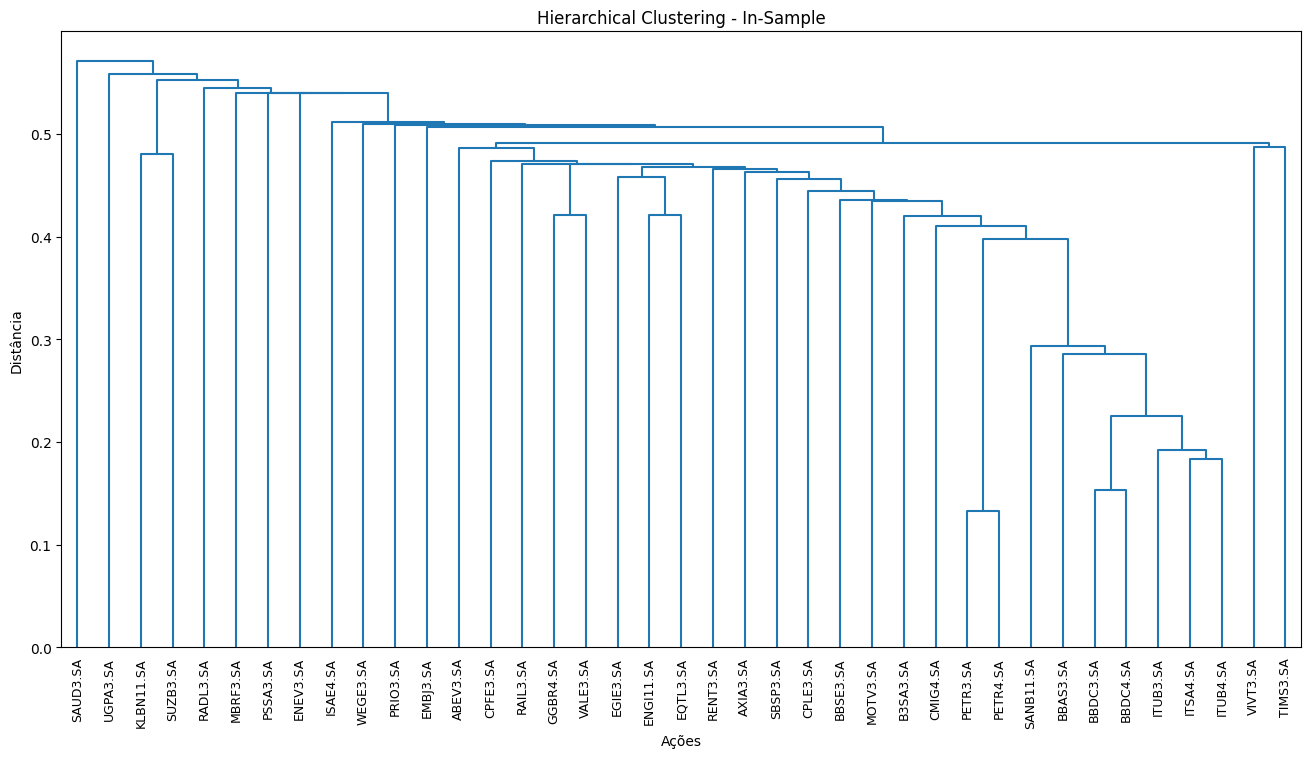

In [8]:
plt.figure(figsize=(16,8))

dendrogram(
    Z_is,
    labels=returns_is.index,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=0
)

plt.title('Hierarchical Clustering - In-Sample')
plt.xlabel('Ações')
plt.ylabel('Distância')
plt.show()

### Quasi-Diagonalização

Nessa etapa, reorganizamos a matriz de covariância seguindo a ordem estabelecida pela estrutura hierárquica

In [9]:
# Matriz de Covariância In-Sample

cov_is = returns_is.T.cov()

# Obtém a ordem das ações segundo a árvore hierárquica
sort_ix_is = leaves_list(Z_is)

# Identifica os tickers na nova ordem
sorted_tickers_is = returns_is.index[sort_ix_is]

# Matriz de covariância quasi-diagonalizada
cov_sorted_is = cov_is.loc[
    sorted_tickers_is,
    sorted_tickers_is
]

# Matriz de correlação reorganizada (visualização)
corr_sorted_is = corr_is.loc[
    sorted_tickers_is,
    sorted_tickers_is
]

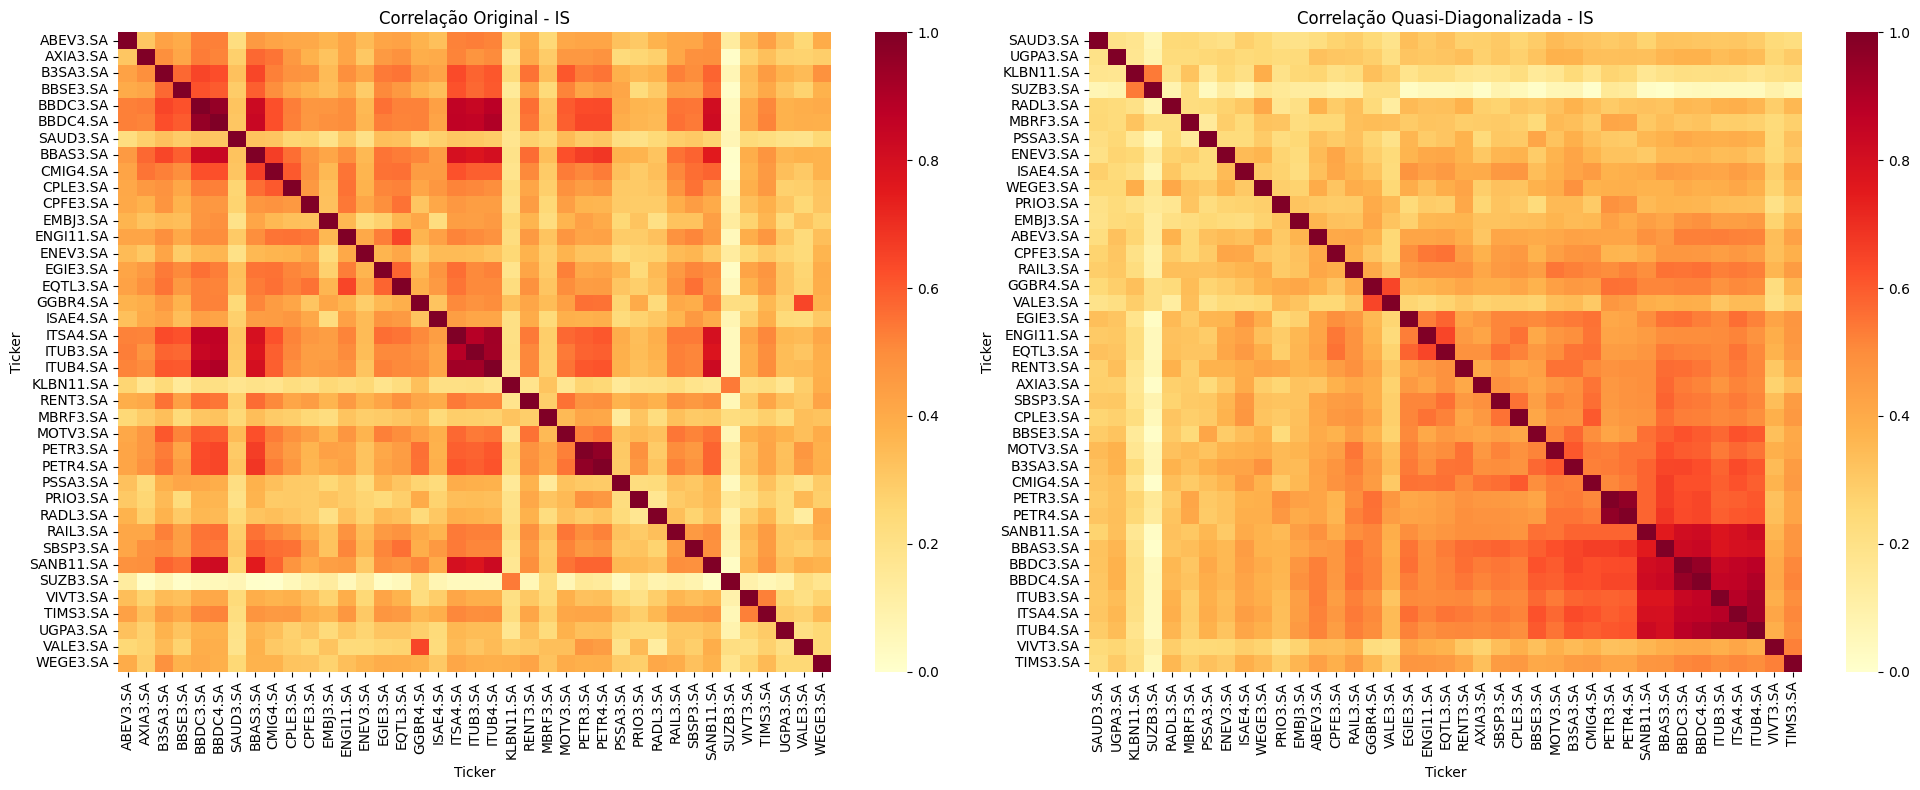

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    corr_is,
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    ax=axes[0]
)

axes[0].set_title('Correlação Original - IS')

sns.heatmap(
    corr_sorted_is,
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    ax=axes[1]
)

axes[1].set_title('Correlação Quasi-Diagonalizada - IS')

plt.tight_layout()
plt.show()

# Calculando a variância de cada cluster

In [11]:
def get_cluster_var(cov_matrix, tickers):

    # Matriz de covariância do cluster
    cov = cov_matrix.loc[tickers, tickers]

    # Pesos inversamente proporcionais às variâncias
    ivp = 1 / np.diag(cov)
    ivp = ivp / ivp.sum()

    # Variância estimada do cluster
    cluster_var = ivp @ cov.values @ ivp

    return cluster_var

# Implementando Recursive Bisection

In [12]:
def recursive_bisection(cov_matrix, sorted_tickers):

    # Inicializa os pesos
    weights = pd.Series(1.0, index=sorted_tickers)

    # Cluster inicial contendo todos os ativos
    clusters = [list(sorted_tickers)]

    while clusters:

        new_clusters = []

        for cluster in clusters:

            if len(cluster) > 1:

                # Divide o cluster em duas metades
                split = len(cluster) // 2

                cluster_1 = cluster[:split]
                cluster_2 = cluster[split:]

                # Variância de cada cluster
                var_1 = get_cluster_var(cov_matrix, cluster_1)
                var_2 = get_cluster_var(cov_matrix, cluster_2)

                # Proporção de capital
                alpha = var_2 / (var_1 + var_2)

                # Atualização dos pesos
                weights.loc[cluster_1] *= alpha
                weights.loc[cluster_2] *= (1 - alpha)

                # Próxima divisão
                new_clusters.extend([cluster_1, cluster_2])

        clusters = new_clusters

    return weights

In [13]:
# Pesos calculados exclusivamente com informações IS
hrp_weights_is = recursive_bisection(
    cov_sorted_is,
    sorted_tickers_is
)

# Ordenar os pesos
hrp_weights_is = hrp_weights_is.sort_values(ascending=False)

# Verificações
assert np.isclose(hrp_weights_is.sum(), 1.0)
assert (hrp_weights_is >= 0).all()
assert np.isfinite(hrp_weights_is).all()

print(hrp_weights_is)
print(f'\nSoma dos pesos: {hrp_weights_is.sum():.4f}')

Ticker
ISAE4.SA     0.074331
SAUD3.SA     0.067244
PSSA3.SA     0.057677
RADL3.SA     0.054426
KLBN11.SA    0.049572
EGIE3.SA     0.043263
CPFE3.SA     0.040578
EQTL3.SA     0.035290
BBSE3.SA     0.033928
ABEV3.SA     0.033768
WEGE3.SA     0.032539
SUZB3.SA     0.031049
ENEV3.SA     0.030752
ENGI11.SA    0.027161
ITUB4.SA     0.025328
ITUB3.SA     0.024838
MBRF3.SA     0.024317
VALE3.SA     0.023165
ITSA4.SA     0.021722
VIVT3.SA     0.020733
RAIL3.SA     0.020297
B3SA3.SA     0.017456
EMBJ3.SA     0.017439
TIMS3.SA     0.017288
GGBR4.SA     0.016903
SANB11.SA    0.016617
CPLE3.SA     0.015167
MOTV3.SA     0.015050
RENT3.SA     0.014063
UGPA3.SA     0.013649
SBSP3.SA     0.012061
BBAS3.SA     0.011562
PETR4.SA     0.010298
PRIO3.SA     0.009503
CMIG4.SA     0.009310
BBDC4.SA     0.008159
AXIA3.SA     0.008119
BBDC3.SA     0.008028
PETR3.SA     0.007349
dtype: float64

Soma dos pesos: 1.0000


### Calculando a volatilidade estimada In-Sample

In [15]:
# Alinhar os pesos à matriz de covariância
w_is = hrp_weights_is.reindex(cov_is.index).values

# Variância diária estimada
portfolio_var_is = w_is @ cov_is.values @ w_is

# Volatilidade anualizada
portfolio_vol_is = np.sqrt(portfolio_var_is * 252)

print(f'Volatilidade anualizada IS: {portfolio_vol_is:.2%}')

Volatilidade anualizada IS: 20.64%


### Backtest Out of Sample

In [16]:
# Capital inicial
initial_capital = 100

# Pesos iniciais do HRP alinhados aos ativos
w_oos = hrp_weights_is.reindex(returns_oos.index)

# Verificação
assert w_oos.notna().all()
assert np.isclose(w_oos.sum(), 1.0)

# Evolução acumulada do valor de cada ativo
asset_growth = (1 + returns_oos.T).cumprod()

# Valor diário de cada posição
position_values = asset_growth.mul(
    w_oos * initial_capital,
    axis=1
)

# Valor total do portfólio
portfolio_value_oos = position_values.sum(axis=1)

# Retorno no primeiro dia OOS em relação ao capital inicial
portfolio_returns_oos = portfolio_value_oos.pct_change()

portfolio_returns_oos.iloc[0] = (
    portfolio_value_oos.iloc[0] / initial_capital - 1
)

In [19]:
def calculate_sharpe(returns, rf_annual=0.0):

    rf_daily = (1 + rf_annual) ** (1 / 252) - 1

    excess_returns = returns.dropna() - rf_daily

    sharpe = (
        excess_returns.mean() /
        excess_returns.std(ddof=1)
    ) * np.sqrt(252)

    return sharpe

In [20]:
# Retorno acumulado OOS
return_hrp = portfolio_value_oos.iloc[-1] / initial_capital - 1

# Volatilidade anualizada realizada OOS
vol_hrp = portfolio_returns_oos.std(ddof=1) * np.sqrt(252)

# CAGR
n_years = len(portfolio_returns_oos) / 252

cagr_hrp = (
    portfolio_value_oos.iloc[-1] / initial_capital
) ** (1 / n_years) - 1

# Sharpe com taxa livre de risco zero
sharpe_hrp = calculate_sharpe(
    portfolio_returns_oos,
    rf_annual=0.0
)

# Resultados
print(f'Retorno acumulado HRP: {return_hrp:.2%}')
print(f'CAGR HRP: {cagr_hrp:.2%}')
print(f'Volatilidade estimada IS: {portfolio_vol_is:.2%}')
print(f'Volatilidade realizada OOS: {vol_hrp:.2%}')
print(f'Sharpe HRP: {sharpe_hrp:.4f}')

Retorno acumulado HRP: 89.15%
CAGR HRP: 13.75%
Volatilidade estimada IS: 20.64%
Volatilidade realizada OOS: 14.62%
Sharpe HRP: 0.9543


### Calculo Portfólio Markowitz

In [21]:
# Número de ativos
n_assets = len(cov_is)

# Função objetivo: variância do portfólio
def portfolio_variance(weights, cov_matrix):
    return weights @ cov_matrix @ weights

# Pesos iniciais iguais
initial_weights = np.ones(n_assets) / n_assets

# Restrições
constraints = ({
    'type': 'eq',
    'fun': lambda w: np.sum(w) - 1
})



In [22]:
# Limites: pesos entre 0 e 1 (sem short selling)
bounds = [(0, 1)] * n_assets

# Otimização de mínima variância
result = minimize(
    portfolio_variance,
    initial_weights,
    args=(cov_is.values * 252,),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-12, 'maxiter': 10000}
)

# Verificar convergência
if not result.success:
    raise RuntimeError(result.message)

# Criar a variável com os pesos ótimos
markowitz_weights_is = pd.Series(
    result.x,
    index=cov_is.index
)

# Verificações
assert np.isclose(markowitz_weights_is.sum(), 1.0)
assert (markowitz_weights_is >= -1e-10).all()

print(markowitz_weights_is.sort_values(ascending=False))

Ticker
ISAE4.SA     2.487216e-01
PSSA3.SA     1.153071e-01
SUZB3.SA     1.046702e-01
SAUD3.SA     9.114323e-02
VIVT3.SA     9.051454e-02
EGIE3.SA     7.107276e-02
CPFE3.SA     6.889105e-02
KLBN11.SA    6.486528e-02
RADL3.SA     6.254011e-02
BBSE3.SA     5.597700e-02
ABEV3.SA     2.181577e-02
VALE3.SA     4.481397e-03
PRIO3.SA     1.704232e-17
WEGE3.SA     8.342825e-18
TIMS3.SA     7.996087e-18
CPLE3.SA     6.372641e-18
EMBJ3.SA     6.360362e-18
ITSA4.SA     6.360189e-18
MOTV3.SA     6.109381e-18
RAIL3.SA     5.507499e-18
SANB11.SA    3.578295e-18
PETR3.SA     1.093459e-18
UGPA3.SA     4.827138e-19
BBDC4.SA     0.000000e+00
BBDC3.SA     0.000000e+00
AXIA3.SA     0.000000e+00
B3SA3.SA     0.000000e+00
RENT3.SA     0.000000e+00
CMIG4.SA     0.000000e+00
ENGI11.SA    0.000000e+00
ENEV3.SA     0.000000e+00
BBAS3.SA     0.000000e+00
ITUB4.SA     0.000000e+00
ITUB3.SA     0.000000e+00
EQTL3.SA     0.000000e+00
GGBR4.SA     0.000000e+00
PETR4.SA     0.000000e+00
MBRF3.SA     0.000000e+00
SBSP3

In [24]:
# Soma dos pesos do portfólio Markowitz
print(f'Soma dos pesos: {markowitz_weights_is.sum():.10f}')
print(f'Total alocado: {markowitz_weights_is.sum():.2%}')

Soma dos pesos: 1.0000000000
Total alocado: 100.00%


In [25]:
w_mkw = markowitz_weights_is.reindex(cov_is.index).values

var_mkw_is = w_mkw @ cov_is.values @ w_mkw

vol_mkw_is = np.sqrt(var_mkw_is * 252)

print(f'Volatilidade estimada IS - Markowitz: {vol_mkw_is:.2%}')
print(f'Volatilidade estimada IS - HRP: {portfolio_vol_is:.2%}')

Volatilidade estimada IS - Markowitz: 16.61%
Volatilidade estimada IS - HRP: 20.64%


### Backtest Markowitz Out of Sample

In [26]:
# Capital inicial
initial_capital = 100

# Alinhar os pesos aos ativos OOS
w_mkw_oos = markowitz_weights_is.reindex(returns_oos.index)

assert w_mkw_oos.notna().all()
assert np.isclose(w_mkw_oos.sum(), 1.0)

# Evolução acumulada de cada ativo
asset_growth_mkw = (1 + returns_oos.T).cumprod()

# Valor diário das posições
position_values_mkw = asset_growth_mkw.mul(
    w_mkw_oos * initial_capital,
    axis=1
)

# Valor diário do portfólio
portfolio_value_mkw = position_values_mkw.sum(axis=1)

# Retornos diários realizados
portfolio_returns_mkw = portfolio_value_mkw.pct_change()

# Incluir o primeiro retorno em relação ao capital inicial
portfolio_returns_mkw.iloc[0] = (
    portfolio_value_mkw.iloc[0] / initial_capital - 1
)

In [27]:
# Retorno acumulado
return_mkw = portfolio_value_mkw.iloc[-1] / initial_capital - 1

# Volatilidade anualizada realizada
vol_mkw = portfolio_returns_mkw.std(ddof=1) * np.sqrt(252)

# CAGR
n_years = len(portfolio_returns_mkw) / 252

cagr_mkw = (
    portfolio_value_mkw.iloc[-1] / initial_capital
) ** (1 / n_years) - 1

# Sharpe com taxa livre de risco zero
sharpe_mkw = calculate_sharpe(
    portfolio_returns_mkw,
    rf_annual=0.0
)

print(f'Retorno acumulado Markowitz: {return_mkw:.2%}')
print(f'CAGR Markowitz: {cagr_mkw:.2%}')
print(f'Volatilidade OOS Markowitz: {vol_mkw:.2%}')
print(f'Sharpe Markowitz: {sharpe_mkw:.4f}')

Retorno acumulado Markowitz: 66.92%
CAGR Markowitz: 10.91%
Volatilidade OOS Markowitz: 13.82%
Sharpe Markowitz: 0.8185


In [29]:
comparison = pd.DataFrame({
    'HRP': {
        'Retorno Acumulado': return_hrp,
        'CAGR': cagr_hrp,
        'Volatilidade Anualizada': vol_hrp,
        'Sharpe': sharpe_hrp
    },
    'Markowitz (GMV)': {
        'Retorno Acumulado': return_mkw,
        'CAGR': cagr_mkw,
        'Volatilidade Anualizada': vol_mkw,
        'Sharpe': sharpe_mkw
    }
}).T

display(
    comparison.style.format({
        'Retorno Acumulado': '{:.2%}',
        'CAGR': '{:.2%}',
        'Volatilidade Anualizada': '{:.2%}',
        'Sharpe': '{:.4f}'
    })
)

,Retorno Acumulado,CAGR,Volatilidade Anualizada,Sharpe
HRP,89.15%,13.75%,14.62%,0.9543
Markowitz (GMV),66.92%,10.91%,13.82%,0.8185


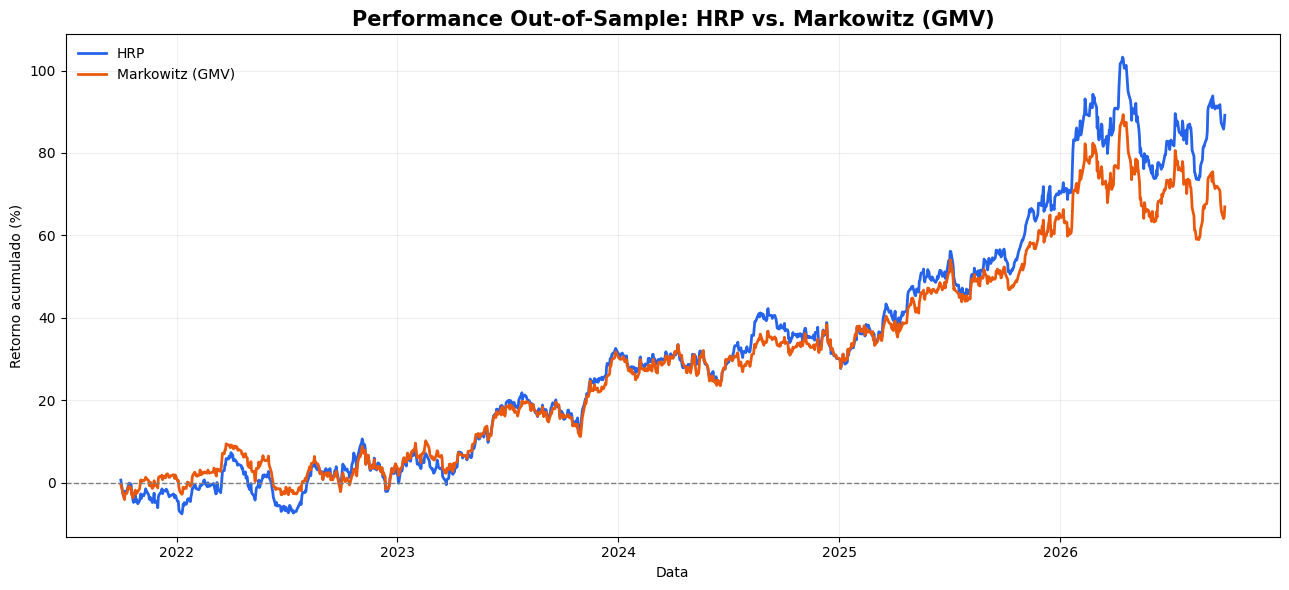

In [30]:
import matplotlib.pyplot as plt

# Retornos acumulados dos portfólios
cum_returns_hrp = (portfolio_value_oos / initial_capital - 1) * 100
cum_returns_mkw = (portfolio_value_mkw / initial_capital - 1) * 100

# Gráfico
plt.figure(figsize=(13, 6))

plt.plot(
    cum_returns_hrp.index,
    cum_returns_hrp,
    label='HRP',
    color='#2563EB',
    linewidth=2
)

plt.plot(
    cum_returns_mkw.index,
    cum_returns_mkw,
    label='Markowitz (GMV)',
    color='#EA580C',
    linewidth=2
)

# Linha de referência
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

# Formatação
plt.title(
    'Performance Out-of-Sample: HRP vs. Markowitz (GMV)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Data')
plt.ylabel('Retorno acumulado (%)')

plt.legend(frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()